In [1]:
# # STEP 1 - Install libraries (Colab already has TF/pandas/sklearn; add kagglehub + seaborn)
# !pip install -q kagglehub seaborn

# # STEP 2 - Kaggle authentication (Colab)
# # On kaggle.com: Settings -> API -> "Create New Token" downloads kaggle.json.
# # Run this cell and upload that kaggle.json when the button appears.
# from google.colab import files
# files.upload()                       # <-- select your kaggle.json here
# import os
# os.makedirs("/root/.kaggle", exist_ok=True)
# !cp kaggle.json /root/.kaggle/kaggle.json
# !chmod 600 /root/.kaggle/kaggle.json

# # STEP 3 - Download the BreakHis dataset
# import kagglehub
# path = kagglehub.dataset_download("ambarish/breakhis")
# print("Dataset downloaded to:", path)

In [2]:
# ===== COLAB SETUP - run this INSTEAD of the cell above =====
# In Colab, skip cell 0 entirely; this cell replaces it.

# 1) Libraries. -U matters: Colab's bundled kagglehub can be out of date.
!pip install -q -U kagglehub seaborn

# 2) Kaggle auth from Colab Secrets. Sidebar key icon -> add KAGGLE_USERNAME
#    and KAGGLE_KEY (the two values inside kaggle.json) -> enable notebook
#    access. Set once and it survives every future session: no re-upload.
import os
from google.colab import userdata
os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
os.environ["KAGGLE_KEY"]      = userdata.get("KAGGLE_KEY")

# 3) Mount Drive so results, checkpoints and runtimes survive a disconnect.
from google.colab import drive
drive.mount("/content/drive")

# 4) Confirm the GPU is active: Runtime -> Change runtime type -> T4 GPU
import tensorflow as tf
gpus = tf.config.list_physical_devices("GPU")
print("GPUs available:", gpus)
if not gpus:
    print("WARNING: no GPU detected. Runtime -> Change runtime type -> T4 GPU.")

# 5) Download the dataset. It stays on fast local disk, NOT on Drive -
#    reading 7,909 small PNGs through the Drive mount is far slower.
import kagglehub
path = kagglehub.dataset_download("ambarish/breakhis")
print("Path to dataset files:", path)

Mounted at /content/drive
GPUs available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Using Colab cache for faster access to the 'breakhis' dataset.
Path to dataset files: /kaggle/input/breakhis


In [3]:
# --- per-cell runtime logging: run this cell ONCE ---
import time, pandas as pd
from IPython import get_ipython
CELL_TIMES, _s = [], {"n": 0}
def _pre(info): _s["t"], _s["n"] = time.perf_counter(), _s["n"] + 1
def _post(res):
    if "t" not in _s: return                      # skips this setup cell itself
    dt = time.perf_counter() - _s.pop("t")   # pop: an empty cell can fire post w/o pre
    CELL_TIMES.append({"cell": _s["n"], "seconds": round(dt, 3),
                       "label": ((res.info.raw_cell or "").strip().splitlines() or [""])[0][:55]})
    print(f"[cell {_s['n']}] runtime: {dt:.2f}s")
def runtime_table():
    df = pd.DataFrame(CELL_TIMES); df.to_csv(OUTPUT_DIR / "cell_runtimes_undersampling.csv", index=False); return df
get_ipython().events.register("pre_run_cell", _pre)
get_ipython().events.register("post_run_cell", _post)

In [4]:
# Confirm a GPU is active:  Runtime -> Change runtime type -> T4 GPU -> Save
import tensorflow as tf
gpus = tf.config.list_physical_devices("GPU")
print("GPUs available:", gpus)
if not gpus:
    print("WARNING: no GPU detected. Set Runtime -> Change runtime type -> T4 GPU.")

GPUs available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
[cell 1] runtime: 0.00s


# 1 Dataset Loading

In [5]:
import kagglehub
import os, pathlib, shutil

# Download BreakHis dataset via KaggleHub
path = kagglehub.dataset_download("ambarish/breakhis")
print("Dataset downloaded to:", path)

# Walk the top-level structure
print("\nTop-level directory contents:")
for item in sorted(os.listdir(path)):
    print(" ", item)

Using Colab cache for faster access to the 'breakhis' dataset.
Dataset downloaded to: /kaggle/input/breakhis

Top-level directory contents:
  BreaKHis_v1
  Folds.csv
[cell 2] runtime: 0.64s


In [6]:
import pandas as pd
import numpy as np
from pathlib import Path

DATASET_ROOT = Path(path)
# Local output folder, created next to this notebook (Colab used a different path).
OUTPUT_DIR   = Path("/content/outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

IMG_EXTENSIONS = {".png", ".jpg", ".jpeg", ".tif", ".bmp"}

# Recursively discover all image files
records = []
for img_path in DATASET_ROOT.rglob("*"):
    if img_path.suffix.lower() in IMG_EXTENSIONS:
        # Determine class from parent folder structure
        # BreakHis structure: .../breast/benign/... or .../breast/malignant/...
        parts = img_path.parts
        label = None
        for part in parts:
            if part.lower() == "benign":
                label = "benign"
                break
            elif part.lower() == "malignant":
                label = "malignant"
                break
        if label is not None:
            records.append({"image_path": str(img_path), "class_label": label})

df = pd.DataFrame(records)
print(f"Total images found: {len(df)}")
print(df["class_label"].value_counts())
df.head()

Total images found: 7909
class_label
malignant    5429
benign       2480
Name: count, dtype: int64


,image_path,class_label
0,/kaggle/input/breakhis/BreaKHis_v1/BreaKHis_v1...,malignant
1,/kaggle/input/breakhis/BreaKHis_v1/BreaKHis_v1...,malignant
2,/kaggle/input/breakhis/BreaKHis_v1/BreaKHis_v1...,malignant
3,/kaggle/input/breakhis/BreaKHis_v1/BreaKHis_v1...,malignant
4,/kaggle/input/breakhis/BreaKHis_v1/BreaKHis_v1...,malignant


[cell 3] runtime: 4.11s


In [7]:
# ===== COLAB: send all outputs to Drive =====
# Must run AFTER the cell above, which sets OUTPUT_DIR to an ephemeral local
# path that Colab wipes when the runtime recycles. This re-points it at Drive.
# Both notebooks use the SAME folder, so the Section 12 oversampling-vs-
# undersampling comparison can finally find both results CSVs.
OUTPUT_DIR = Path("/content/drive/MyDrive/breakhis_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("OUTPUT_DIR ->", OUTPUT_DIR)
print("Dataset stays on local disk ->", DATASET_ROOT)

OUTPUT_DIR -> /content/drive/MyDrive/breakhis_outputs
Dataset stays on local disk -> /kaggle/input/breakhis
[cell 4] runtime: 0.22s


# 2 Dataset Exploration

In [8]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import random, warnings
warnings.filterwarnings("ignore")

print("=" * 55)
print("DATASET SUMMARY")
print("=" * 55)
print(f"Total images          : {len(df)}")
print(f"Classes               : {df['class_label'].unique().tolist()}")
print(f"Benign images         : {(df['class_label']=='benign').sum()}")
print(f"Malignant images      : {(df['class_label']=='malignant').sum()}")
print(f"Class imbalance ratio : {(df['class_label']=='malignant').sum()/(df['class_label']=='benign').sum():.2f}")
print("=" * 55)

DATASET SUMMARY
Total images          : 7909
Classes               : ['malignant', 'benign']
Benign images         : 2480
Malignant images      : 5429
Class imbalance ratio : 2.19
[cell 5] runtime: 0.01s


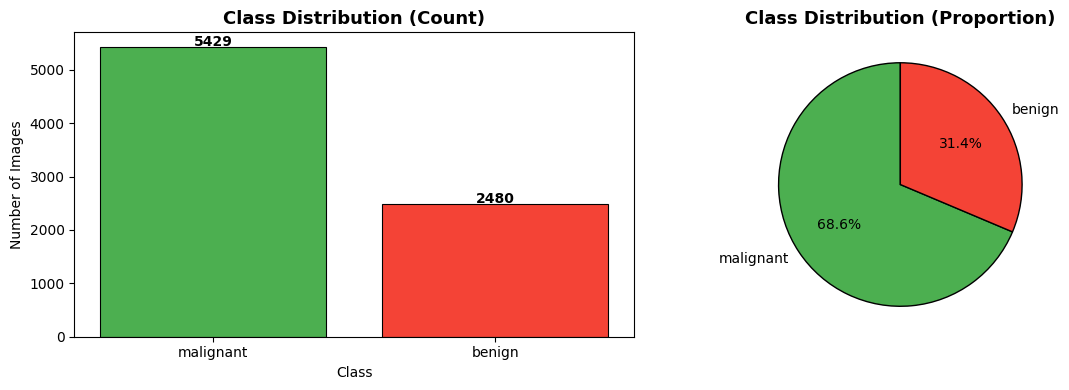

[cell 6] runtime: 1.79s


In [9]:
# Class distribution chart
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

counts = df["class_label"].value_counts()
colors = ["#4CAF50", "#F44336"]

axes[0].bar(counts.index, counts.values, color=colors, edgecolor="black", linewidth=0.8)
axes[0].set_title("Class Distribution (Count)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Class")
axes[0].set_ylabel("Number of Images")
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 20, str(v), ha="center", fontweight="bold")

axes[1].pie(counts.values, labels=counts.index, autopct="%1.1f%%",
            colors=colors, startangle=90, wedgeprops={"edgecolor": "black"})
axes[1].set_title("Class Distribution (Proportion)", fontsize=13, fontweight="bold")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

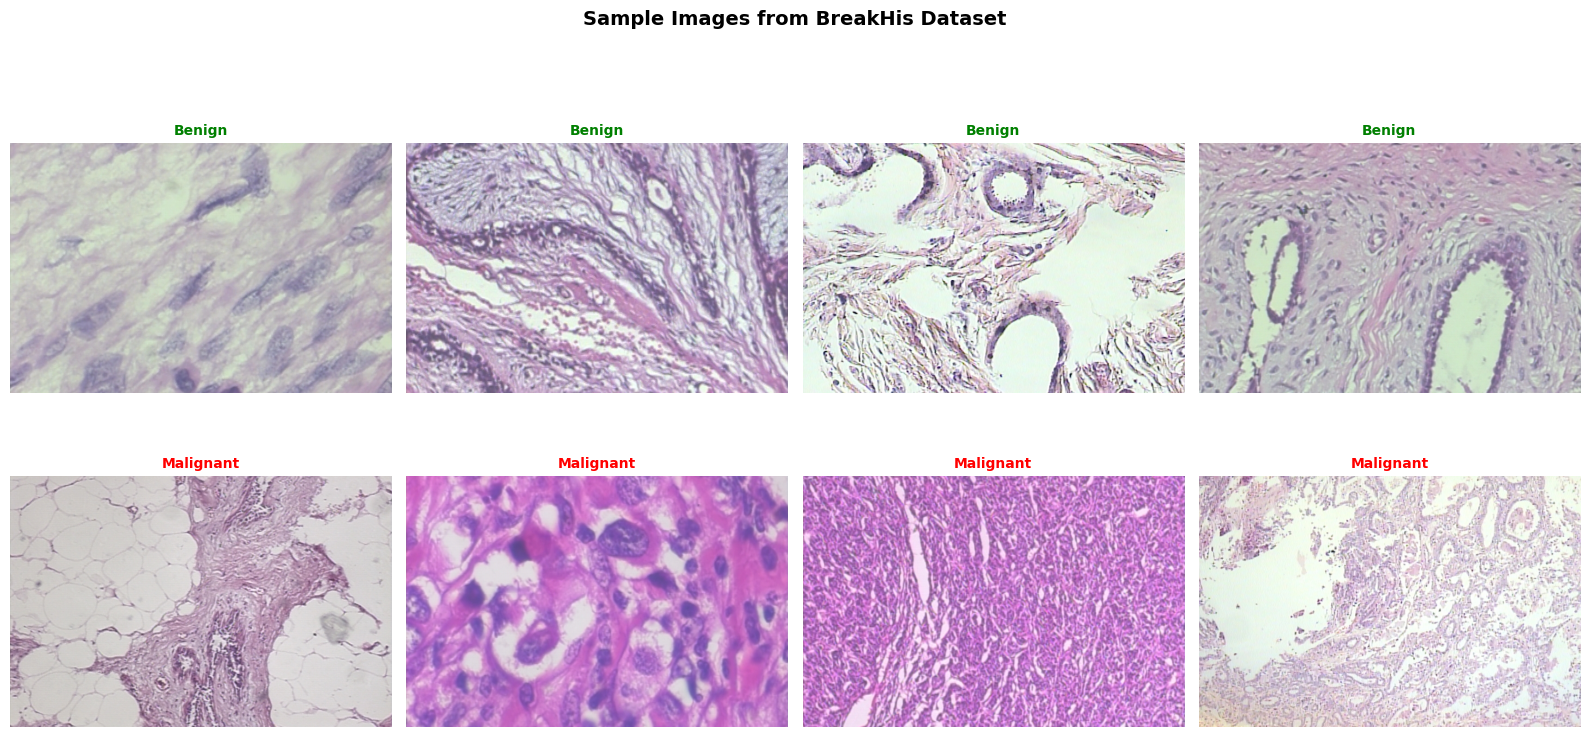

[cell 7] runtime: 7.38s


In [10]:
# Random image visualization (4 benign + 4 malignant)
benign_samples    = df[df["class_label"] == "benign"].sample(4, random_state=42)
malignant_samples = df[df["class_label"] == "malignant"].sample(4, random_state=42)
samples = pd.concat([benign_samples, malignant_samples])

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, (_, row) in zip(axes.flatten(), samples.iterrows()):
    try:
        img = mpimg.imread(row["image_path"])
        ax.imshow(img)
        ax.set_title(row["class_label"].capitalize(), fontsize=10,
                     color="green" if row["class_label"] == "benign" else "red",
                     fontweight="bold")
    except Exception:
        ax.set_title("Error", color="grey")
    ax.axis("off")

plt.suptitle("Sample Images from BreakHis Dataset", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "sample_images.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
# Dataset summary table
summary = pd.DataFrame({
    "Metric": ["Total Images", "Benign", "Malignant", "Image Extensions"],
    "Value": [
        len(df),
        (df["class_label"] == "benign").sum(),
        (df["class_label"] == "malignant").sum(),
        ", ".join(df["image_path"].apply(lambda x: Path(x).suffix.lower()).unique())
    ]
})
print(summary.to_string(index=False))

          Metric Value
    Total Images  7909
          Benign  2480
       Malignant  5429
Image Extensions  .png
[cell 8] runtime: 0.28s


# 3 Data Cleaning

In [12]:
from PIL import Image
import io

def is_valid_image(path):
    """Return True if image can be opened and decoded correctly."""
    try:
        with Image.open(path) as img:
            img.verify()
        return True
    except Exception:
        return False

print("Scanning for corrupted images...")
df["is_valid"] = df["image_path"].apply(is_valid_image)

invalid_count = (~df["is_valid"]).sum()
print(f"Total images  : {len(df)}")
print(f"Valid images  : {df['is_valid'].sum()}")
print(f"Invalid images: {invalid_count}")

Scanning for corrupted images...
Total images  : 7909
Valid images  : 7909
Invalid images: 0
[cell 9] runtime: 51.84s


In [13]:
# Remove invalid images
df_clean = df[df["is_valid"]].copy().reset_index(drop=True)
df_clean.drop(columns=["is_valid"], inplace=True)

print(f"Dataset after cleaning: {len(df_clean)} images")
print(df_clean["class_label"].value_counts())

Dataset after cleaning: 7909 images
class_label
malignant    5429
benign       2480
Name: count, dtype: int64
[cell 10] runtime: 0.01s


# 4 Data Preprocessing

In [14]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import load_img, img_to_array

IMG_SIZE    = (224, 224)
BATCH_SIZE  = 32
NUM_CLASSES = 1   # binary classification

# Label encoding: benign=0, malignant=1
df_clean["label"] = (df_clean["class_label"] == "malignant").astype(int)

print("Label distribution:")
print(df_clean["label"].value_counts())
print(f"\nImage target size: {IMG_SIZE}")
print(f"Batch size       : {BATCH_SIZE}")

Label distribution:
label
1    5429
0    2480
Name: count, dtype: int64

Image target size: (224, 224)
Batch size       : 32
[cell 11] runtime: 0.01s


In [15]:
# Verify a single image load + normalise pipeline
sample_path = df_clean["image_path"].iloc[0]
img = load_img(sample_path, target_size=IMG_SIZE)
arr = img_to_array(img) / 255.0
print(f"Sample image shape : {arr.shape}")
print(f"Pixel value range  : [{arr.min():.3f}, {arr.max():.3f}]")

Sample image shape : (224, 224, 3)
Pixel value range  : [0.188, 1.000]
[cell 12] runtime: 0.03s


# 5 Data Augmentation

In [16]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Training augmentation
train_datagen = ImageDataGenerator(
    rescale=1.0 / 255.0,
    rotation_range=20,
    horizontal_flip=True,
    zoom_range=0.15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    fill_mode="nearest"
)

# Validation / test — only rescale
val_test_datagen = ImageDataGenerator(rescale=1.0 / 255.0)

print("Training augmentation configuration:")
print("  Rescale          : 1/255")
print("  Rotation range   : 20 degrees")
print("  Horizontal flip  : True")
print("  Zoom range       : 0.15")
print("  Width shift      : 0.1")
print("  Height shift     : 0.1")

Training augmentation configuration:
  Rescale          : 1/255
  Rotation range   : 20 degrees
  Horizontal flip  : True
  Zoom range       : 0.15
  Width shift      : 0.1
  Height shift     : 0.1
[cell 13] runtime: 0.00s


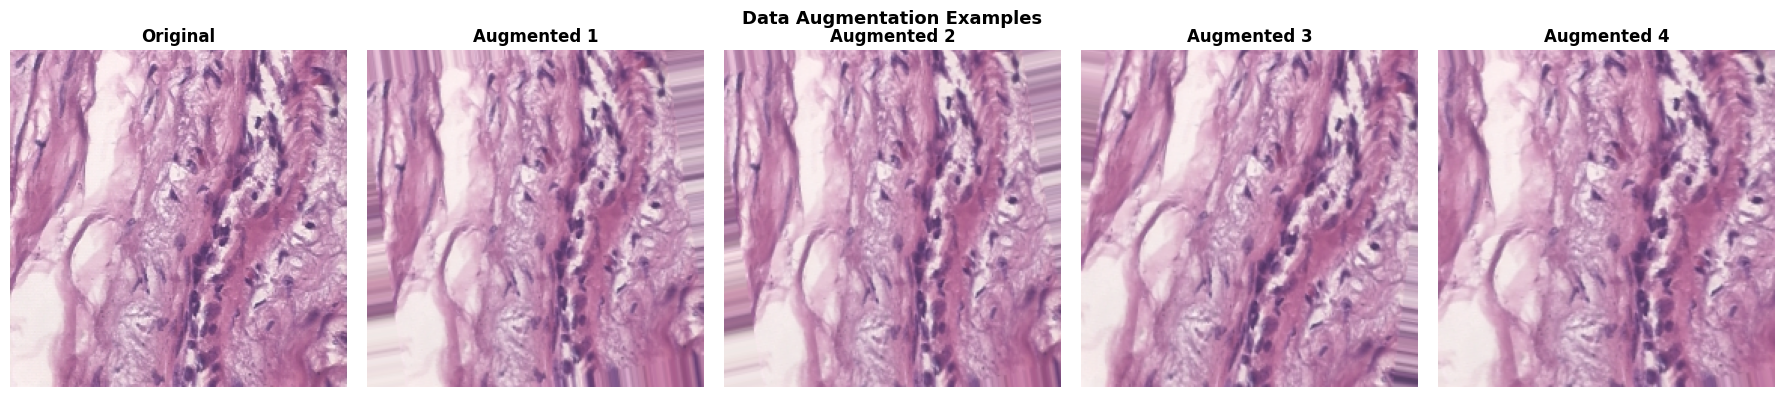

[cell 14] runtime: 2.64s


In [17]:
# Visualise augmented samples
sample_img_path = df_clean[df_clean["class_label"] == "malignant"]["image_path"].iloc[0]
orig_img = load_img(sample_img_path, target_size=IMG_SIZE)
orig_arr = img_to_array(orig_img)
orig_arr_exp = orig_arr.reshape((1,) + orig_arr.shape)

aug_gen = ImageDataGenerator(
    rotation_range=20,
    horizontal_flip=True,
    zoom_range=0.15,
    fill_mode="nearest"
)

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
axes[0].imshow(orig_arr.astype("uint8"))
axes[0].set_title("Original", fontweight="bold")
axes[0].axis("off")

for i, batch in enumerate(aug_gen.flow(orig_arr_exp, batch_size=1)):
    axes[i + 1].imshow(batch[0].astype("uint8"))
    axes[i + 1].set_title(f"Augmented {i+1}", fontweight="bold")
    axes[i + 1].axis("off")
    if i == 3:
        break

plt.suptitle("Data Augmentation Examples", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "augmentation_examples.png", dpi=150, bbox_inches="tight")
plt.show()

# 6 Train Validation Test Split

In [18]:
from sklearn.model_selection import train_test_split

# Stratified split: 70% train, 15% val, 15% test
df_train, df_temp = train_test_split(
    df_clean, test_size=0.30, stratify=df_clean["label"], random_state=42
)
df_val, df_test = train_test_split(
    df_temp, test_size=0.50, stratify=df_temp["label"], random_state=42
)

print(f"Training set   : {len(df_train)} images  | benign={( df_train['label']==0).sum()}  malignant={( df_train['label']==1).sum()}")
print(f"Validation set : {len(df_val)} images  | benign={( df_val['label']==0).sum()}  malignant={( df_val['label']==1).sum()}")
print(f"Test set       : {len(df_test)} images  | benign={( df_test['label']==0).sum()}  malignant={( df_test['label']==1).sum()}")
print(f"\nTotal         : {len(df_train)+len(df_val)+len(df_test)} images")

Training set   : 5536 images  | benign=1736  malignant=3800
Validation set : 1186 images  | benign=372  malignant=814
Test set       : 1187 images  | benign=372  malignant=815

Total         : 7909 images
[cell 15] runtime: 0.30s


# 7 Class Balancing

In [19]:
# 7 Class Balancing - UNDERSAMPLING (training set only)
# Balance ONLY the training data. Validation and test keep their natural distribution.
from sklearn.utils import resample
counts = df_train["label"].value_counts()
maj_label, min_label = counts.idxmax(), counts.idxmin()
df_maj = df_train[df_train["label"] == maj_label]
df_min = df_train[df_train["label"] == min_label]
df_maj_under = resample(df_maj, replace=False, n_samples=len(df_min), random_state=42)
df_train_bal = pd.concat([df_maj_under, df_min]).sample(frac=1, random_state=42).reset_index(drop=True)
print("Before balancing:"); print(df_train["label"].value_counts())
print("\nAfter UNDERSAMPLING:"); print(df_train_bal["label"].value_counts())
SAMPLING_METHOD = "Undersampling"

Before balancing:
label
1    3800
0    1736
Name: count, dtype: int64

After UNDERSAMPLING:
label
1    1736
0    1736
Name: count, dtype: int64
[cell 16] runtime: 0.01s


In [20]:
# --- Run configuration (Colab GPU) ---
# A Colab T4 GPU can handle full-size images. If you ever hit an out-of-memory
# error, set LOW_MEMORY = True to drop to 128x128 / batch 16.
LOW_MEMORY = False
if LOW_MEMORY:
    IMG_SIZE   = (128, 128)
    BATCH_SIZE = 16
print("IMG_SIZE:", IMG_SIZE, "| BATCH_SIZE:", BATCH_SIZE)

IMG_SIZE: (224, 224) | BATCH_SIZE: 32
[cell 17] runtime: 0.00s


In [21]:
# Generators. Training uses the BALANCED dataframe; validation/test unchanged.
df_train_bal["label_str"] = df_train_bal["class_label"]
df_val["label_str"]  = df_val["class_label"]
df_test["label_str"] = df_test["class_label"]

train_generator = train_datagen.flow_from_dataframe(
    df_train_bal, x_col="image_path", y_col="label_str",
    target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode="binary", shuffle=True, seed=42)
val_generator = val_test_datagen.flow_from_dataframe(
    df_val, x_col="image_path", y_col="label_str",
    target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode="binary", shuffle=False)
test_generator = val_test_datagen.flow_from_dataframe(
    df_test, x_col="image_path", y_col="label_str",
    target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode="binary", shuffle=False)
print("Class indices:", train_generator.class_indices)

Found 3472 validated image filenames belonging to 2 classes.
Found 1186 validated image filenames belonging to 2 classes.
Found 1187 validated image filenames belonging to 2 classes.
Class indices: {'benign': 0, 'malignant': 1}
[cell 18] runtime: 1.88s


# 8 Hyperparameters

In [22]:
# 8 Hyperparameters
from tensorflow.keras import callbacks
HP = {"img_size": IMG_SIZE, "batch_size": BATCH_SIZE, "epochs": 15,
      "learning_rate": 1e-4, "dropout": 0.5, "optimizer": "adam"}
print("Hyperparameters:")
for k, v in HP.items(): print(f"  {k}: {v}")

def make_callbacks(tag):
    return [
        callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
        callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, verbose=1),
        callbacks.ModelCheckpoint(filepath=str(OUTPUT_DIR / f"best_{tag}_{SAMPLING_METHOD}.keras"),
                                  monitor="val_accuracy", mode="max", save_best_only=True),
    ]

Hyperparameters:
  img_size: (224, 224)
  batch_size: 32
  epochs: 15
  learning_rate: 0.0001
  dropout: 0.5
  optimizer: adam
[cell 19] runtime: 0.00s


# 9 Models (Custom CNN, DenseNet121, MobileNetV2)

In [23]:
# 9 Models: define builders (each model is created only when needed, to save memory)
from tensorflow.keras import layers, Model, optimizers
from tensorflow.keras.applications import DenseNet121, MobileNetV2

INPUT_SHAPE = (IMG_SIZE[0], IMG_SIZE[1], 3)

def build_custom_cnn():
    inputs = layers.Input(shape=INPUT_SHAPE)
    x = inputs
    for f in [32, 64, 128, 256]:
        x = layers.Conv2D(f, (3, 3), activation="relu", padding="same")(x)
        x = layers.BatchNormalization()(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(HP["dropout"])(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    return Model(inputs, outputs, name="CustomCNN")

def build_transfer(base_fn, name):
    base = base_fn(include_top=False, weights="imagenet", input_shape=INPUT_SHAPE)
    base.trainable = False
    inputs = layers.Input(shape=INPUT_SHAPE)
    x = base(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(HP["dropout"])(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    return Model(inputs, outputs, name=name)

# Builders are callables so only one model exists in memory at a time.
model_builders = {
    "MobileNetV2": lambda: build_transfer(MobileNetV2, "MobileNetV2"),  # lightest
    "CustomCNN":   build_custom_cnn,
    "DenseNet121": lambda: build_transfer(DenseNet121, "DenseNet121"),  # heaviest
}
# On a low-memory M1, start with the lighter two and add DenseNet121 once stable:
MODELS_TO_RUN = ["MobileNetV2", "CustomCNN", "DenseNet121"]

[cell 20] runtime: 0.00s


# 10 Training and Evaluation (memory-safe)


Training: MobileNetV2 | Undersampling
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/15
109/109 ━━━━━━━━━━━━━━━━━━━━ 154s 1s/step - accuracy: 0.6031 - loss: 0.7074 - val_accuracy: 0.6931 - val_loss: 0.5616 - learning_rate: 1.0000e-04
Epoch 2/15
109/109 ━━━━━━━━━━━━━━━━━━━━ 156s 951ms/step - accuracy: 0.6849 - loss: 0.6012 - val_accuracy: 0.7167 - val_loss: 0.5399 - learning_rate: 1.0000e-04
Epoch 3/15
109/109 ━━━━━━━━━━━━━━━━━━━━ 103s 938ms/step - accuracy: 0.7120 - loss: 0.5551 - val_accuracy: 0.7546 - val_loss: 0.4995 - learning_rate: 1.0000e-04
Epoch 4/15
109/109 ━━━━━━━━━━━━━━━━━━━━ 106s 976ms/step - accuracy: 0.7160 - loss: 0.5494 - val_accuracy: 0.7378 - val_loss: 0.5147 - learning_rate: 1.0000e-04
Epoch 5/15
109/109 ━━━━━━━━━━━━━━━━━━━━ 0s 786ms/step - accuracy: 0.7428 - loss: 0.5201
Epoch 5: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.
109/109 ━━━━━━━━━━━━━━━━━━━━ 102s 937ms/step - accuracy: 0.7471 - loss: 0.5242 - val_accuracy: 0.7268 - val_los

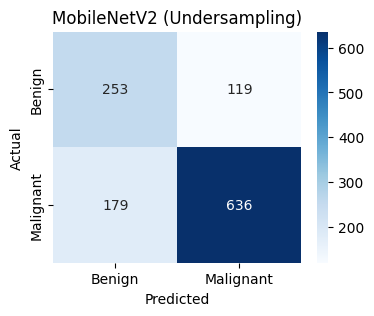


Training: CustomCNN | Undersampling
Epoch 1/15
109/109 ━━━━━━━━━━━━━━━━━━━━ 124s 1s/step - accuracy: 0.7710 - loss: 0.4781 - val_accuracy: 0.6863 - val_loss: 0.6447 - learning_rate: 1.0000e-04
Epoch 2/15
109/109 ━━━━━━━━━━━━━━━━━━━━ 103s 946ms/step - accuracy: 0.8137 - loss: 0.3960 - val_accuracy: 0.6863 - val_loss: 0.6977 - learning_rate: 1.0000e-04
Epoch 3/15
109/109 ━━━━━━━━━━━━━━━━━━━━ 104s 953ms/step - accuracy: 0.8353 - loss: 0.3676 - val_accuracy: 0.6880 - val_loss: 0.6305 - learning_rate: 1.0000e-04
Epoch 4/15
109/109 ━━━━━━━━━━━━━━━━━━━━ 105s 962ms/step - accuracy: 0.8528 - loss: 0.3350 - val_accuracy: 0.7462 - val_loss: 0.5724 - learning_rate: 1.0000e-04
Epoch 5/15
109/109 ━━━━━━━━━━━━━━━━━━━━ 104s 957ms/step - accuracy: 0.8690 - loss: 0.3119 - val_accuracy: 0.8297 - val_loss: 0.3596 - learning_rate: 1.0000e-04
Epoch 6/15
109/109 ━━━━━━━━━━━━━━━━━━━━ 104s 959ms/step - accuracy: 0.8715 - loss: 0.2969 - val_accuracy: 0.8744 - val_loss: 0.3034 - learning_rate: 1.0000e-04
Epoch 

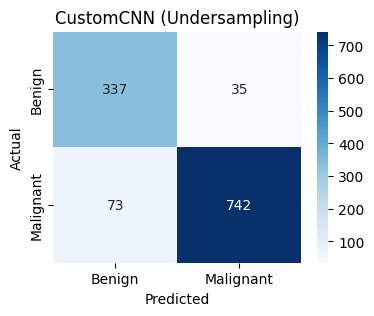


Training: DenseNet121 | Undersampling
29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/15
109/109 ━━━━━━━━━━━━━━━━━━━━ 176s 1s/step - accuracy: 0.6135 - loss: 0.6635 - val_accuracy: 0.7116 - val_loss: 0.5872 - learning_rate: 1.0000e-04
Epoch 2/15
109/109 ━━━━━━━━━━━━━━━━━━━━ 104s 953ms/step - accuracy: 0.7183 - loss: 0.5496 - val_accuracy: 0.7858 - val_loss: 0.5071 - learning_rate: 1.0000e-04
Epoch 3/15
109/109 ━━━━━━━━━━━━━━━━━━━━ 105s 958ms/step - accuracy: 0.7586 - loss: 0.5030 - val_accuracy: 0.8263 - val_loss: 0.4545 - learning_rate: 1.0000e-04
Epoch 4/15
109/109 ━━━━━━━━━━━━━━━━━━━━ 108s 991ms/step - accuracy: 0.7892 - loss: 0.4726 - val_accuracy: 0.8415 - val_loss: 0.4172 - learning_rate: 1.0000e-04
Epoch 5/15
109/109 ━━━━━━━━━━━━━━━━━━━━ 104s 955ms/step - accuracy: 0.8024 - loss: 0.4524 - val_accuracy: 0.8423 - val_loss: 0.4191 - learning_rate: 1.0000e-04
Epoch 6/15
109/109 ━━━━━━━━━━━━━━━━━━━━ 0s 784ms/step - accuracy: 0.8009 - loss: 0.4343
Epoch 6: ReduceLROnPlatea

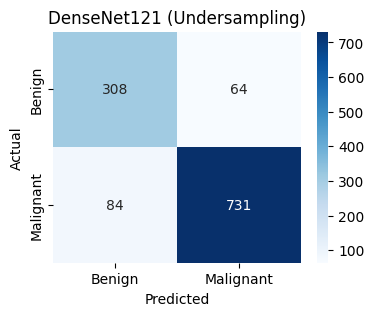

[cell 21] runtime: 3959.31s


In [24]:
# 10 Train and evaluate each model ONE AT A TIME (memory-safe for M1)
import gc, numpy as np, seaborn as sns, tensorflow as tf
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, classification_report)

y_true = df_test["label"].astype(int).values
results, histories = [], {}

for name in MODELS_TO_RUN:
    print("\n" + "=" * 60); print("Training:", name, "|", SAMPLING_METHOD); print("=" * 60)
    tf.keras.backend.clear_session(); gc.collect()

    model = model_builders[name]()
    model.compile(optimizer=optimizers.Adam(HP["learning_rate"]),
                  loss="binary_crossentropy", metrics=["accuracy"])
    h = model.fit(train_generator, validation_data=val_generator,
                  epochs=HP["epochs"], callbacks=make_callbacks(name), verbose=1)
    histories[name] = h.history

    test_generator.reset()
    probs = model.predict(test_generator, verbose=0).flatten()
    preds = (probs >= 0.5).astype(int)
    results.append({"Model": name, "Sampling": SAMPLING_METHOD,
        "Accuracy": accuracy_score(y_true, preds), "Precision": precision_score(y_true, preds),
        "Recall": recall_score(y_true, preds), "F1": f1_score(y_true, preds),
        "ROC_AUC": roc_auc_score(y_true, probs)})
    print("\n" + name + " - classification report\n")
    print(classification_report(y_true, preds, target_names=["Benign", "Malignant"]))
    cm = confusion_matrix(y_true, preds)
    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["Benign", "Malignant"], yticklabels=["Benign", "Malignant"])
    plt.title(f"{name} ({SAMPLING_METHOD})"); plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.show()

    del model; gc.collect()   # free memory before the next model

# 11 Performance Metrics

Performance summary (Undersampling):
      Model      Sampling  Accuracy  Precision  Recall     F1  ROC_AUC
MobileNetV2 Undersampling    0.7489     0.8424  0.7804 0.8102   0.8046
  CustomCNN Undersampling    0.9090     0.9550  0.9104 0.9322   0.9721
DenseNet121 Undersampling    0.8753     0.9195  0.8969 0.9081   0.9291
Saved: /content/drive/MyDrive/breakhis_outputs/results_undersampling.csv


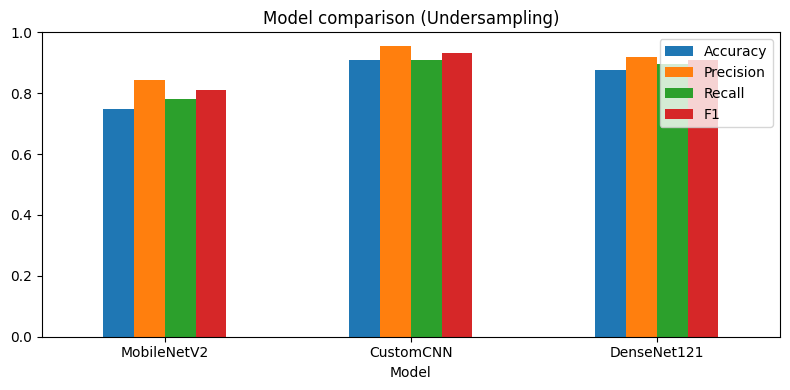

[cell 22] runtime: 0.23s


In [25]:
# 11 Performance summary (performance matrix)
results_df = pd.DataFrame(results)
print("Performance summary (" + SAMPLING_METHOD + "):")
print(results_df.round(4).to_string(index=False))

csv_path = OUTPUT_DIR / f"results_{SAMPLING_METHOD.lower()}.csv"
results_df.to_csv(csv_path, index=False)
print("Saved:", csv_path)

ax = results_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1"]].plot.bar(figsize=(8, 4))
ax.set_title(f"Model comparison ({SAMPLING_METHOD})"); ax.set_ylim(0, 1)
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

# 12 Oversampling vs Undersampling Comparison

      Model      Sampling  Accuracy  Precision  Recall     F1  ROC_AUC
  CustomCNN  Oversampling    0.8930     0.9538  0.8871 0.9193   0.9673
DenseNet121  Oversampling    0.8955     0.9379  0.9080 0.9227   0.9522
MobileNetV2  Oversampling    0.7767     0.8906  0.7693 0.8255   0.8574
MobileNetV2 Undersampling    0.7489     0.8424  0.7804 0.8102   0.8046
  CustomCNN Undersampling    0.9090     0.9550  0.9104 0.9322   0.9721
DenseNet121 Undersampling    0.8753     0.9195  0.8969 0.9081   0.9291


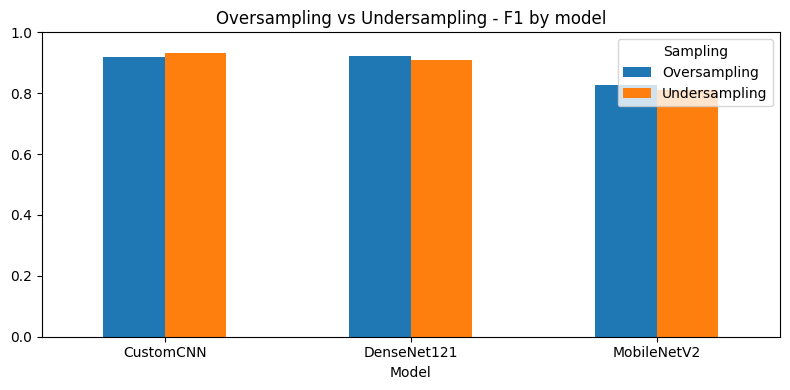

[cell 23] runtime: 0.47s


In [26]:
# 12 Comparison: Oversampling vs Undersampling
# Run BOTH notebooks once each (they save a results CSV to OUTPUT_DIR), then run this.
import os
paths = {"Oversampling": OUTPUT_DIR / "results_oversampling.csv",
         "Undersampling": OUTPUT_DIR / "results_undersampling.csv"}
frames = [pd.read_csv(p) for p in paths.values() if os.path.exists(p)]
if len(frames) < 2:
    print("Run BOTH the oversampling and undersampling notebooks first,")
    print("then re-run this cell to see the side-by-side comparison.")
else:
    comp = pd.concat(frames, ignore_index=True)
    print(comp.round(4).to_string(index=False))
    pivot = comp.pivot(index="Model", columns="Sampling", values="F1")
    ax = pivot.plot.bar(figsize=(8, 4))
    ax.set_title("Oversampling vs Undersampling - F1 by model")
    ax.set_ylim(0, 1); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

In [27]:
# Per-cell runtime summary (written to OUTPUT_DIR)
df = runtime_table()
print(df.to_string(index=False))
print(f"\nTotal runtime: {df.seconds.sum():.1f}s ({df.seconds.sum()/60:.1f} min)")

 cell  seconds                                                   label
    1    0.002 # Confirm a GPU is active:  Runtime -> Change runtime t
    2    0.640                                        import kagglehub
    3    4.108                                     import pandas as pd
    4    0.222          # ===== COLAB: send all outputs to Drive =====
    5    0.008                         import matplotlib.pyplot as plt
    6    1.788                              # Class distribution chart
    7    7.384   # Random image visualization (4 benign + 4 malignant)
    8    0.283                                 # Dataset summary table
    9   51.840                                   from PIL import Image
   10    0.008                                 # Remove invalid images
   11    0.011                                 import tensorflow as tf
   12    0.026       # Verify a single image load + normalise pipeline
   13    0.003 from tensorflow.keras.preprocessing.image import ImageD
   14 